<p>This notebook is used to load and transform United Nations General Assembly Voting data for Analysis.  Some simple analysis is performed dirtly in the notebook, but the overall objective is preformat the data for use in a Tableau dashboard.  The final section of this notebook is performing cluster analysis on GDP x US Voting Coincidence.</p>

<p>Python3 is required as well as following packages.  See the repo README.md for more details.</p>
<ul>
    <li>openpyxl - Used to as the engine when loading XLS files via Pandas</li>
    <li>tableauhyperapi - Reuired to write .hyper file extract for Tabluea</li>
    <li>pantab - Helper module to simplify data type mapping between Pandas dataframs and Hyper extracts</li>
</ul>

<hr />

In [1]:
import re
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import tableauhyperapi as hyper
import pantab
from datetime import date
sns.set()
sns.set_style('whitegrid')

In [2]:
source_path = './source_data/'
source_file = f'{source_path}/NortheasternExport4.xlsx'
df = pd.read_excel(source_file, engine='openpyxl')

<b>Core UN Voiting data</b>
<p>This the main input file and the first sheet is read. The ResolutionCode column is important as it's used later to merge the category data. The VotingInformation column contains the string payload of votes by country. The column names are in MARC format (<a href='https://research.un.org/en/digitallibrary/export'>https://research.un.org/en/digitallibrary/export</a>). The column name mapping and definitions have been taken from the voting manual found here: <a href='https://www.un.org/depts/dhl/unbisref_manual/voting/voting.htm'>https://www.un.org/depts/dhl/unbisref_manual/voting/voting.htm</a></p>

In [3]:
# Static column mapping
columns = {1: 'ID', '191__a': 'UNDocumentSymbol', '791__a': 'ResolutionSymbol', '245__a': 'TitleStatement', 
           992: 'ActionDate', 996: 'VoteNote', '793__a': 'CommitteeName', '991__c': 'AgendaTitle', 
           '991__d': 'AgendaSubject', '993__a': 'RelatedDocumentSymbols', 967: 'VotingInformation', 
           '650__a': 'TopicSubjects'}

In [4]:
df.rename(columns=columns, inplace=True)
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14439 entries, 0 to 14438
Data columns (total 12 columns):
 #   Column                  Non-Null Count  Dtype         
---  ------                  --------------  -----         
 0   ID                      14439 non-null  int64         
 1   UNDocumentSymbol        7356 non-null   object        
 2   ResolutionSymbol        7083 non-null   object        
 3   TitleStatement          14438 non-null  object        
 4   ActionDate              14431 non-null  datetime64[ns]
 5   VoteNote                9030 non-null   object        
 6   CommitteeName           7829 non-null   object        
 7   AgendaTitle             14428 non-null  object        
 8   AgendaSubject           14423 non-null  object        
 9   RelatedDocumentSymbols  14424 non-null  object        
 10  VotingInformation       1682 non-null   object        
 11  TopicSubjects           7297 non-null   object        
dtypes: datetime64[ns](1), int64(1), object(10)
mem

In [5]:
# Illustrate the contents of the VotingInformation 
df[(df.VotingInformation.notnull())][['ID', 'VotingInformation']].head(3)

,ID,VotingInformation
372,422519,1; AFG; AFGHANISTAN; 2; ALB; ALBANIA; 3; DZA; ...
394,426217,1; AFG; Y; AFGHANISTAN; 2; ALB; Y; ALBANIA; 3;...
418,426984,1; AFG; AFGHANISTAN; 2; ALB; A; ALBANIA; 3; DZ...


In [6]:
def parse_voting_information(df):
    """
    Parse voting information form dataframe with ID and VotingInformation columns
    Returns: nested dictionary in the form {ID: {CountryCode: Vote}, ...}
    """
    votes_by_id = dict()
    cntry_to_cntry_name = dict()
    for index, row in df.iterrows():
        un_voting_id = row['ID']
        votes = row['VotingInformation']

        # Split the string into a list, changing elements at each numeric character instance
        vote_list = re.split(r'(\D+)', votes)
        # Reduce the list to only the character elements
        vote_list = [x for x in vote_list if not x.isnumeric()]
        
        votes = {}
        for vote in vote_list:
            vote_split = vote.split(';')
            if len(vote_split) > 1:
                country_code = vote_split[1].strip()
                # Avoid empty country code cases
                if len(country_code) > 0:
                    # This first case only applies to Zambia (last country)
                    # the only missing vote info while cntry is there
                    if len(vote_split) > 1 and len(vote_split) < 4:
                        votes[country_code] = np.NaN
                    # Zambia is the last country in the list and has no trailing space char
                    elif len(vote_split) == 4:
                        if vote_split[2].strip() in ['Y', 'N', 'A']:
                            votes[country_code] = vote_split[2].strip()
                            cntry_to_cntry_name[country_code] = vote_split[3].strip()
                    elif len(vote_split) >= 5:
                        votes[country_code] = vote_split[2].strip()
                        cntry_to_cntry_name[country_code] = vote_split[3].strip()
        votes_by_id[un_voting_id] = votes
    return votes_by_id, cntry_to_cntry_name

In [7]:
# Filter source data to only rows that include voting information values
ff = df[(df.VotingInformation.notnull())][['ID', 'VotingInformation']]\

# Split the combined country / vote string into parts by ID
res, cntry_to_cntry_name = parse_voting_information(df=ff)

# Confirm the resulting dict object has the same number of rows as the input frame
print(f'Frame row count: {df[df.VotingInformation.notnull()].shape[0]} | processed dict key count: {len(res.keys())}')

Frame row count: 1682 | processed dict key count: 1682


In [8]:
# Matrix of Country x ID of vote values Y, N and NaN (not attended)
xf = pd.DataFrame(res)
xf.head()

,422519,426217,426984,426989,426997,427081,427520,427521,427522,427523,...,3895476,3896178,3896179,3896180,3896181,3896182,3896183,3897076,3897077,3897078
DZA,Y,Y,Y,Y,Y,Y,Y,Y,Y,Y,...,Y,Y,Y,Y,Y,Y,Y,Y,Y,Y
AND,Y,Y,Y,Y,A,Y,N,A,Y,A,...,Y,Y,Y,N,Y,Y,A,Y,Y,Y
AGO,Y,Y,Y,Y,Y,NaN,Y,Y,Y,Y,...,NaN,Y,Y,A,A,Y,A,Y,Y,Y
ATG,Y,Y,Y,Y,Y,A,Y,Y,Y,Y,...,Y,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
ARG,Y,Y,Y,Y,Y,Y,A,A,Y,A,...,Y,Y,Y,Y,Y,Y,Y,Y,Y,Y


In [9]:
def score_votes(df, root_cntry='USA', target_cntry='CHN'):
    """
    Score votes according to the "voting coincidence" methodology
    Returns Pandas Series 
    """
    # Assign Root and Target country Series
    r = df.loc[root_cntry]
    t = df.loc[target_cntry]

    # Output Series is copy of the target country Series
    o = t.copy()

    # Apply the conditional logic to the arrays
    o.loc[r == t] = 1  # Same
    o.loc[r != t] = 0  # Opposite
    o.loc[(r.isin(['Y', 'N'])) & (t == 'A')] = .5  # Partial, either direction
    o.loc[(t.isin(['Y', 'N'])) & (r == 'A')] = .5  # Partial, either direction
    
    # For resolutions adopted by acclaim, the vote of every country is assinge "same" (=1) 
    # and calcualted accordingly, How to identify these cases?

    # Ensure that NaN (Absent) votes are correctly retained
    o.loc[t.isnull()] = np.NaN  # Absent
    return o

In [10]:
all_dat = []
for root_cntry in xf.index:
    dat = []
    # Iterate over all of the countries in the xf frame index, applying scoring to the row-wise series
    for target_cntry in xf.index:
        # Need to include USA as the output frame is used for total vote counts
        dat.append(score_votes(df=xf, root_cntry=root_cntry, target_cntry=target_cntry))

    # Recreate the frame with scores inplace of vote strings 
    nf = pd.DataFrame(dat)
    print(f'Coincidence Country: {root_cntry} Original voting frame shape: {xf.shape} | '
          f'scored vote frame shape: {nf.shape}')
    
    # Prepend the Coincidence Country to the multiindex
    nf = pd.concat({root_cntry: nf}, names=['CoincidenceCountry'])
    all_dat.append(nf)
nf = pd.concat(all_dat)

Coincidence Country: DZA Original voting frame shape: (195, 1682) | scored vote frame shape: (195, 1682)
Coincidence Country: AND Original voting frame shape: (195, 1682) | scored vote frame shape: (195, 1682)
Coincidence Country: AGO Original voting frame shape: (195, 1682) | scored vote frame shape: (195, 1682)
Coincidence Country: ATG Original voting frame shape: (195, 1682) | scored vote frame shape: (195, 1682)
Coincidence Country: ARG Original voting frame shape: (195, 1682) | scored vote frame shape: (195, 1682)
Coincidence Country: ARM Original voting frame shape: (195, 1682) | scored vote frame shape: (195, 1682)
Coincidence Country: AUS Original voting frame shape: (195, 1682) | scored vote frame shape: (195, 1682)
Coincidence Country: AUT Original voting frame shape: (195, 1682) | scored vote frame shape: (195, 1682)
Coincidence Country: AZE Original voting frame shape: (195, 1682) | scored vote frame shape: (195, 1682)
Coincidence Country: BHR Original voting frame shape: (

Coincidence Country: PHL Original voting frame shape: (195, 1682) | scored vote frame shape: (195, 1682)
Coincidence Country: POL Original voting frame shape: (195, 1682) | scored vote frame shape: (195, 1682)
Coincidence Country: PRT Original voting frame shape: (195, 1682) | scored vote frame shape: (195, 1682)
Coincidence Country: QAT Original voting frame shape: (195, 1682) | scored vote frame shape: (195, 1682)
Coincidence Country: KOR Original voting frame shape: (195, 1682) | scored vote frame shape: (195, 1682)
Coincidence Country: ROU Original voting frame shape: (195, 1682) | scored vote frame shape: (195, 1682)
Coincidence Country: RUS Original voting frame shape: (195, 1682) | scored vote frame shape: (195, 1682)
Coincidence Country: SMR Original voting frame shape: (195, 1682) | scored vote frame shape: (195, 1682)
Coincidence Country: SAU Original voting frame shape: (195, 1682) | scored vote frame shape: (195, 1682)
Coincidence Country: SGP Original voting frame shape: (

Coincidence Country: LCA Original voting frame shape: (195, 1682) | scored vote frame shape: (195, 1682)
Coincidence Country: VCT Original voting frame shape: (195, 1682) | scored vote frame shape: (195, 1682)
Coincidence Country: WSM Original voting frame shape: (195, 1682) | scored vote frame shape: (195, 1682)
Coincidence Country: STP Original voting frame shape: (195, 1682) | scored vote frame shape: (195, 1682)
Coincidence Country: SEN Original voting frame shape: (195, 1682) | scored vote frame shape: (195, 1682)
Coincidence Country: SLE Original voting frame shape: (195, 1682) | scored vote frame shape: (195, 1682)
Coincidence Country: SLB Original voting frame shape: (195, 1682) | scored vote frame shape: (195, 1682)
Coincidence Country: LKA Original voting frame shape: (195, 1682) | scored vote frame shape: (195, 1682)
Coincidence Country: SUR Original voting frame shape: (195, 1682) | scored vote frame shape: (195, 1682)
Coincidence Country: TJK Original voting frame shape: (

In [11]:
nf.loc['USA']

,422519,426217,426984,426989,426997,427081,427520,427521,427522,427523,...,3895476,3896178,3896179,3896180,3896181,3896182,3896183,3897076,3897077,3897078
DZA,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.5,0.5,0.5,...,1.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0
AND,0.0,0.0,0.0,1.0,0.5,0.0,1.0,1.0,0.5,1.0,...,1.0,0.0,0.0,1.0,1.0,1.0,0.5,0.0,0.0,0.0
AGO,0.0,0.0,0.0,1.0,1.0,NaN,0.0,0.5,0.5,0.5,...,NaN,0.0,0.0,0.5,0.5,1.0,0.5,0.0,0.0,0.0
ATG,0.0,0.0,0.0,1.0,1.0,0.5,0.0,0.5,0.5,0.5,...,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
ARG,0.0,0.0,0.0,1.0,1.0,0.0,0.5,1.0,0.5,1.0,...,1.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
LBR,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,1.0,0.0,0.0,NaN,1.0,1.0,NaN,0.0,0.0,0.0
IRQ,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,1.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0
SRB,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,1.0,0.0,0.0,0.0,NaN,NaN,0.5,0.0,0.0,0.0
MNE,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,1.0,0.0,0.0,1.0,1.0,1.0,0.5,0.0,0.0,0.0


In [12]:
# Compute all time voting coincidence
coincidence_country = 'USA'
voting_coincidence = nf.loc[coincidence_country].T.sum().div(nf.loc[coincidence_country].T.count()).multiply(100).sort_values(ascending=False)
voting_coincidence

USA    100.000000
ISR     89.013999
FSM     78.992537
PLW     72.422062
MHL     71.024735
          ...    
ZWE     17.981889
IRN     17.917448
CUB     17.746820
SYR     16.911765
PRK     15.689540
Length: 195, dtype: float64

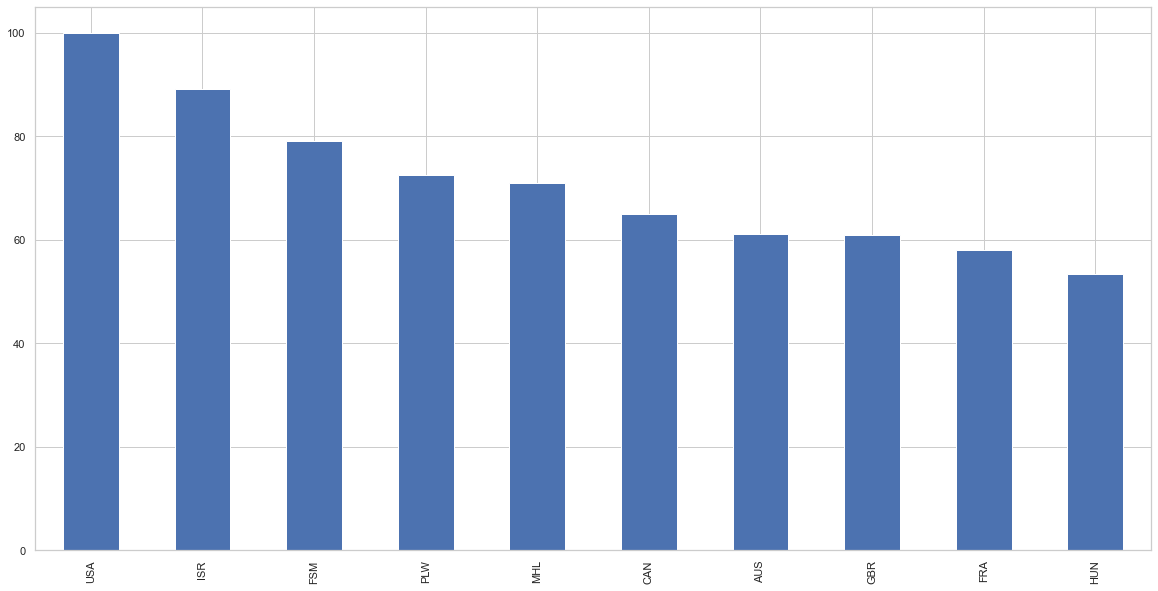

In [13]:
# Plot the top 10 country by voting coincidence with US
ax = voting_coincidence.sort_values(ascending=False).head(10).plot(kind='bar', figsize=(20, 10))

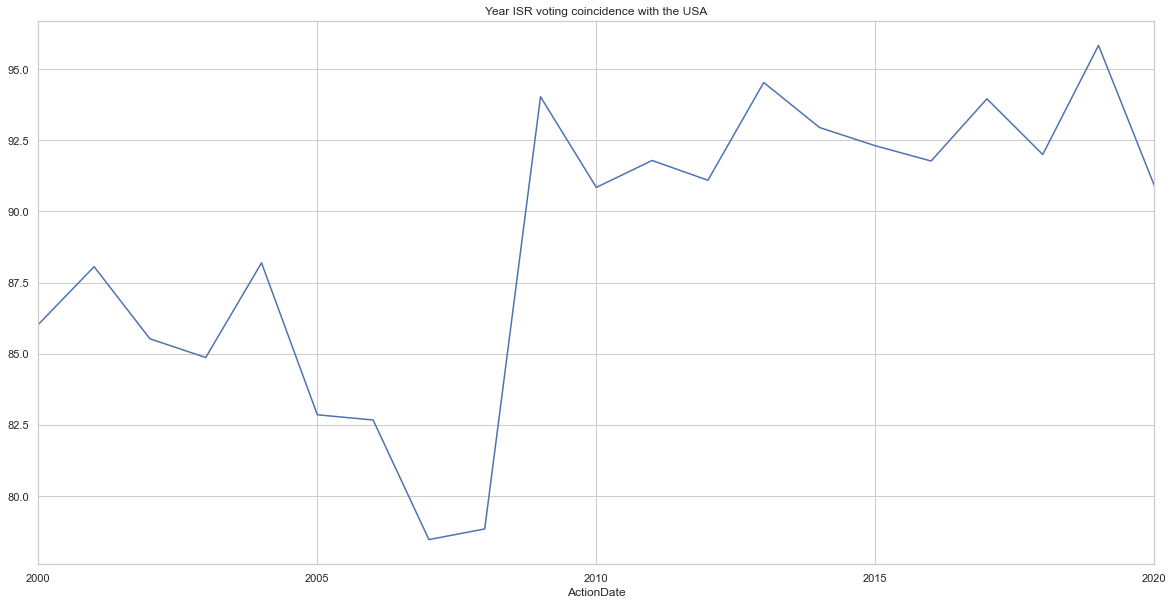

In [14]:
zf = nf.loc[coincidence_country].T.merge(df[df.ActionDate.notnull()], how='left', left_index=True, right_on='ID')
grp = zf.set_index('ActionDate')['ISR'].groupby(pd.Grouper(freq='Y'))
_ = grp.sum().div(grp.count()).multiply(100).plot(
    figsize=(20, 10), title=f'Year ISR voting coincidence with the {coincidence_country}')

In [15]:
##################################################
# Begin cateogry mapping

<b>Category Data</b>
<p>Categories taken from GA Votes Working Document.xlsx - Top level Sub level description tab.  Sheet downloaded as csv from <a href='https://docs.google.com/spreadsheets/d/1cYxtXgdAD2MuCOkzGeTNW7v8TaGeer6d/edit#gid=1743910634'>https://docs.google.com/spreadsheets/d/1cYxtXgdAD2MuCOkzGeTNW7v8TaGeer6d/edit#gid=1743910634</a></p>

In [16]:
##################################################
# Begin cateogry mapping
source_path = './source_data/'
source_file = f'{source_path}/GA Votes Working Document.xlsx - Top level Sub level description.csv'
cf = pd.read_csv(source_file, usecols=[0,1], names=['ID', 'Description']).dropna().reset_index(drop=True)
# Ascending sort order by ID is enforced here since we're forward filling values
cf.sort_values('ID', inplace=True)
cf.head()

,ID,Description
0,1.0,Israeli-Palestinian Issues
1,2.0,Decolonization
2,2.1,Statements of Principle
3,2.2,Geographic/regional cases
4,3.0,Human Rights


In [17]:
# Slice the category ID into top / sub level values
# Derive the TopLevel value based on the ID value (whole numbers only)
cf['TopLevel'] = np.NaN
cf.loc[cf['ID'].apply(float.is_integer), 'TopLevel'] = cf.loc[cf['ID'].apply(float.is_integer), 'ID']
cf['TopLevel'].ffill(inplace=True)

# Derive the SubLevel value based on the ID value (only the floats, indicating the level)
cf['SubLevel'] = np.NaN
cf.loc[cf['ID'].apply(float.is_integer) == False, 'SubLevel'] = cf.loc[cf['ID'].apply(float.is_integer) == False, 'ID']

# Generate top / sub level descriptions to be used as a heirarchy in Tableau
cf['TopLevelDescription'] = np.NaN
cf.loc[cf['ID'].apply(float.is_integer), 'TopLevelDescription'] = cf.loc[cf['ID'].apply(float.is_integer), 'Description']
cf['TopLevelDescription'].ffill(inplace=True)

cf['SubLevelDescription'] = np.NaN
cf.loc[cf['ID'].apply(float.is_integer) == False, 'SubLevelDescription'] = cf.loc[cf['ID'].apply(float.is_integer) == False, 'Description']
cf['SubLevelDescription'].fillna(cf['TopLevelDescription'], inplace=True)

# Add the level numbers as the prefix to the description strings
cf['TopLevelDescription'] = cf['TopLevel'].astype(str) + ' ' + cf['TopLevelDescription']
cf['SubLevelDescription'] = cf['SubLevel'].fillna(cf.TopLevel).astype(str) + ' ' + cf['SubLevelDescription']

# Top the ID & Description columns to avoid confusion
cf.drop(columns=['ID', 'Description'], inplace=True)
# Replace NaN sub level values with top level values, there is only one sub level and the NaNs cause join issues
cf['SubLevel'].fillna(cf['TopLevel'], inplace=True)

In [18]:
cf.head()

,TopLevel,SubLevel,TopLevelDescription,SubLevelDescription
0,1.0,1.0,1.0 Israeli-Palestinian Issues,1.0 Israeli-Palestinian Issues
1,2.0,2.0,2.0 Decolonization,2.0 Decolonization
2,2.0,2.1,2.0 Decolonization,2.1 Statements of Principle
3,2.0,2.2,2.0 Decolonization,2.2 Geographic/regional cases
4,3.0,3.0,3.0 Human Rights,3.0 Human Rights


In [19]:
# Load the vote info x category data - exported from GDrive
source_file = f'{source_path}/GA Votes Working Document.xlsx - Top Level Sub level.csv'
vote_info_to_cats = pd.read_csv(source_file)
vote_info_to_cats.columns
columns = {'Resolution Code': 'ResolutionCode', 'Top Level': 'TopLevel', 'Sub-level': 'SubLevel'}
vote_info_to_cats = vote_info_to_cats.rename(columns=columns)[columns.values()]

# Now merge the vote info x category codes
print(df.shape)
df1 = pd.merge(df[df.ResolutionSymbol.notnull()], vote_info_to_cats, how='left', left_on='ResolutionSymbol', right_on='ResolutionCode')
df2 = pd.merge(df[df.UNDocumentSymbol.notnull()], vote_info_to_cats, how='left', left_on='UNDocumentSymbol', right_on='ResolutionCode')
df = pd.concat([df1, df2])
print(df.shape)

# Replace NaN sub level values with top level values, there is only one sub level and the NaNs cause join issues
df['SubLevel'].fillna(df['TopLevel'], inplace=True)

(14439, 12)
(14439, 15)


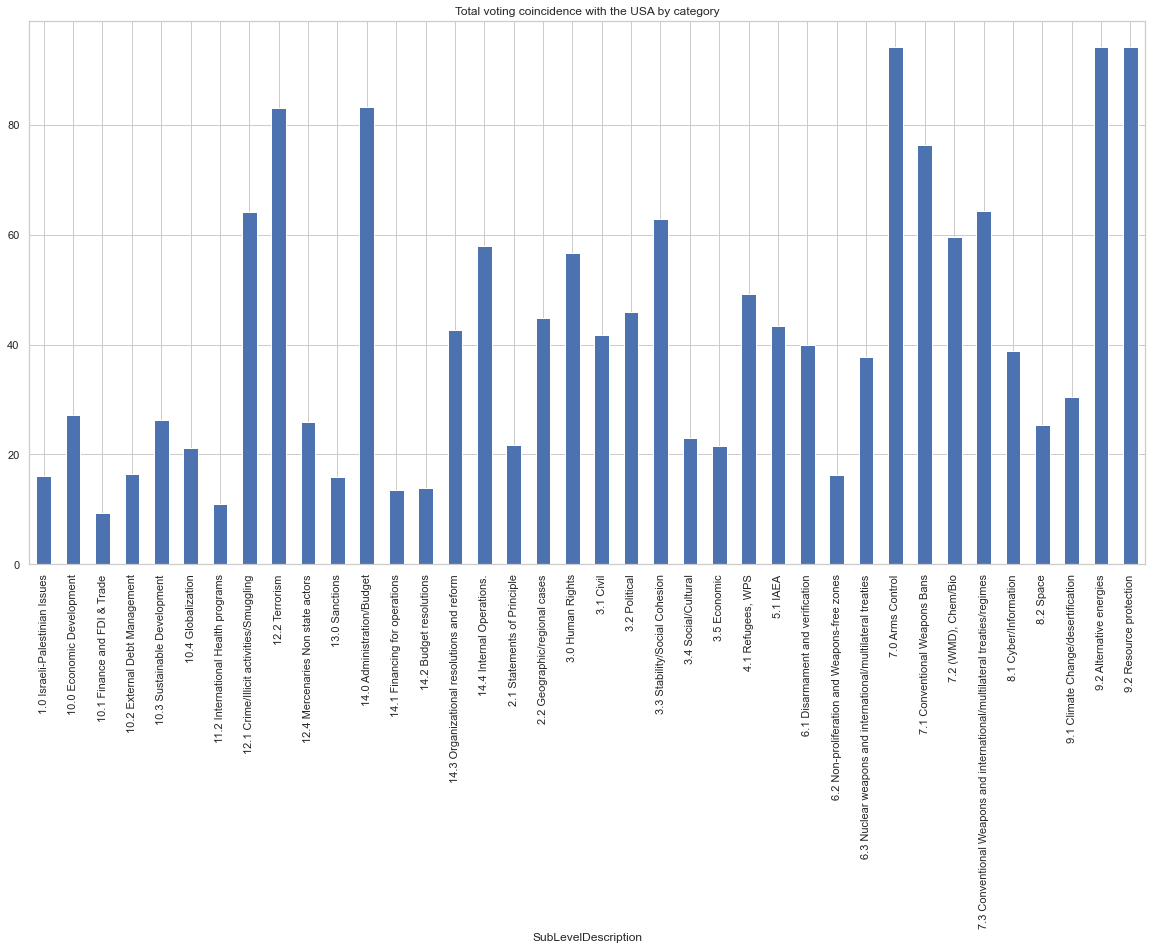

In [20]:
zf = nf.loc[coincidence_country].T.merge(
    df.merge(cf, how='left', on=['TopLevel', 'SubLevel'])[['ID', 'SubLevel', 'SubLevelDescription']], 
                how='left', left_index=True, right_on='ID')
grp = zf[zf.SubLevel.notnull()].drop(columns=['ID', 'SubLevel']).groupby('SubLevelDescription')
_ = grp.sum().div(grp.count()).multiply(100).T.mean().plot(
    kind='bar', figsize=(20, 10), title=f'Total voting coincidence with the {coincidence_country} by category')

In [21]:
# Final data reformatting of vote scores for Tableau
nf_out = nf.unstack().unstack().reset_index().rename(columns={'level_0': 'ID', 'level_1': 'CountryCode', 0: 'Score'})

# Add country names to the original df frame, which ultimately is saved as VoteInfo
nf_out['CountryName'] = nf_out['CountryCode'].map(cntry_to_cntry_name)
nf_out['CoincidenceCountryName'] = nf_out['CoincidenceCountry'].map(cntry_to_cntry_name)

In [22]:
# Export all 3 frames as tables within a single .hyper file
# CommitteeName comtains 4 rows with the integer value of 2, this is causing issues with pantab type detection
df['CommitteeName'] = df['CommitteeName'].map({2: 'Two'})
un_voting_date = {'VoteInfo': df, 'VoteScores': nf_out, 'Categories': cf}
pantab.frames_to_hyper(dict_of_frames=un_voting_date, database='UNVotingData.hyper')

In [23]:
##################################################
# Begin GDP data processing

<b>GDP Data</b>
<p>GDP data by country, year taken from the UN stats site here: <a href='https://unstats.un.org/unsd/snaama/Downloads'>https://unstats.un.org/unsd/snaama/Downloads</a>.  GDP is broken down at it's currenct price in US Dollars for all countries for all years, sorted alphabetically.

In [24]:
# Read the source data file and filter to only GDP values
source_path = './source_data/'
source_file = f'{source_path}/Download-GDPcurrent-USD-countries.xlsx'
gdp = pd.read_excel(source_file, engine='openpyxl', skiprows=2)
gdp = gdp[gdp.IndicatorName == 'Gross Domestic Product (GDP)']
gdp.head()

,CountryID,Country,IndicatorName,1970,1971,1972,1973,1974,1975,1976,...,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019
7,4,Afghanistan,Gross Domestic Product (GDP),1.731436e+09,1.812838e+09,1.647900e+09,1.702716e+09,2.061729e+09,2.319754e+09,2.513581e+09,...,1.469889e+10,1.735069e+10,1.913650e+10,1.962180e+10,1.955070e+10,1.871305e+10,1.803764e+10,1.862303e+10,1.798697e+10,1.787655e+10
24,8,Albania,Gross Domestic Product (GDP),2.265577e+09,2.330585e+09,2.397526e+09,2.466543e+09,2.537016e+09,2.610110e+09,2.685746e+09,...,1.192695e+10,1.289087e+10,1.231978e+10,1.277628e+10,1.322824e+10,1.138692e+10,1.186136e+10,1.301973e+10,1.514703e+10,1.527807e+10
41,12,Algeria,Gross Domestic Product (GDP),5.155121e+09,5.363676e+09,7.176428e+09,9.229622e+09,1.325976e+10,1.555555e+10,1.775003e+10,...,1.612073e+11,2.000191e+11,2.090591e+11,2.097550e+11,2.138100e+11,1.659791e+11,1.600342e+11,1.700972e+11,1.754150e+11,1.711579e+11
58,20,Andorra,Gross Domestic Product (GDP),9.947679e+07,1.131285e+08,1.435060e+08,1.908638e+08,2.360555e+08,2.785143e+08,2.875884e+08,...,3.446566e+09,3.624386e+09,3.188830e+09,3.192603e+09,3.267334e+09,2.788758e+09,2.894646e+09,3.000160e+09,3.218419e+09,3.154137e+09
75,24,Angola,Gross Domestic Product (GDP),3.807846e+09,4.008354e+09,4.103085e+09,5.017414e+09,5.628237e+09,4.148374e+09,3.981810e+09,...,8.379948e+10,1.117897e+11,1.280529e+11,1.367099e+11,1.457122e+11,1.161936e+11,1.011238e+11,1.221239e+11,1.013532e+11,8.500061e+10


In [25]:
# Create matrix of Year / Country for all available UN Voting data - values are Yearly US Voting Coincidence
coincidence_country = 'USA'
zf = nf.loc[coincidence_country].T.merge(df[df.ActionDate.notnull()], how='left', left_index=True, right_on='ID')
zf['Year'] = zf['ActionDate'].dt.year.fillna(0).astype(int)
# Filter and group vote scores by year, compute the US Vote Coincidence
grp = zf[zf.Year != 0].groupby('Year')[nf.loc['USA'].index]
pf = grp.sum().div(grp.count()).multiply(100)
pf

,DZA,AND,AGO,ATG,ARG,ARM,AUS,AUT,AZE,BHR,...,GNB,SOM,TLS,SCG,CAF,LBR,IRQ,SRB,MNE,SSD
Year,,,,,,,,,,,,,,,,,,,,,
2000,29.411765,54.411765,41.346154,32.031250,42.647059,39.552239,55.147059,53.731343,36.718750,29.850746,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2001,22.058824,50.735294,28.448276,22.222222,36.764706,33.088235,52.985075,50.000000,26.612903,22.794118,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2002,19.078947,44.078947,20.895522,20.212766,32.236842,28.666667,50.657895,44.078947,24.324324,19.078947,...,33.333333,13.095238,20.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2003,18.831169,45.454545,25.757576,19.736842,32.467532,30.666667,56.493506,45.454545,22.535211,17.532468,...,17.164179,18.103448,24.637681,46.753247,23.484848,NaN,NaN,NaN,NaN,NaN
2004,15.972222,44.444444,21.296296,19.531250,27.397260,28.767123,59.154930,44.520548,21.527778,15.753425,...,20.000000,15.909091,21.641791,45.205479,20.491803,18.421053,10.784314,NaN,NaN,NaN
2005,15.333333,41.333333,19.117647,14.788732,27.333333,25.342466,58.108108,43.333333,18.493151,15.068493,...,17.968750,13.709677,23.387097,42.000000,16.326531,17.924528,17.857143,NaN,NaN,NaN
2006,16.831683,42.079208,22.282609,19.500000,25.742574,26.767677,54.950495,39.603960,22.043011,19.801980,...,26.612903,10.975610,20.430108,50.000000,21.276596,15.384615,19.473684,41.414141,40.322581,NaN
2007,10.126582,40.506329,19.000000,14.556962,20.253165,22.151899,55.696203,37.341772,16.197183,13.924051,...,8.620690,8.620690,22.916667,NaN,13.043478,12.727273,13.815789,39.610390,41.447368,NaN
2008,12.500000,42.465753,16.438356,16.447368,22.435897,25.000000,52.564103,39.102564,17.763158,15.384615,...,17.391304,5.357143,20.270270,NaN,13.513514,22.142857,16.438356,33.333333,40.789474,NaN


In [26]:
# Reverse the map
cntry_name_to_cntry = {v:k for k, v in cntry_to_cntry_name.items()}

# Mannual map of GDP country names to UN Voting country names
xmap = {'D.P.R. of Korea': "DEMOCRATIC PEOPLE'S REPUBLIC OF KOREA"}
gdp.loc[gdp['Country'].isin(xmap.keys()), 'Country'] = gdp.loc[gdp['Country'].isin(xmap.keys())]['Country'].map(xmap)

gdp['Cntry'] = gdp['Country'].str.upper().map(cntry_name_to_cntry)

# Some of the GDP country codes are historical and do not exist during the UN GA Voting data time series
print(f"Could not map {gdp[gdp['Cntry'].isnull()].shape[0]} countries...")

Could not map 33 countries...


In [27]:
gf = gdp.set_index('Cntry').drop(columns=['CountryID', 'Country', 'IndicatorName']).T
gf.index = gf.index.astype(int)
# Compute mean GDP in USD by country for the same year range as we have UN Voting data
gf = gf.loc[pf.index.min():pf.index.max()].mean()
gf.name = 'GDP'  # Set series name
gf.sort_values(ascending=False).head()

Cntry
USA    1.527613e+13
CHN    6.549079e+12
JPN    4.946020e+12
DEU    3.213194e+12
GBR    2.543648e+12
Name: GDP, dtype: float64

In [28]:
# Average of yearly voting coincidence with USA across all countries
pf.mean().sort_values(ascending=False)

USA    100.000000
ISR     88.930820
FSM     79.649020
PLW     74.949361
MHL     72.105378
          ...    
IRN     18.102329
CUB     17.846437
SYR     17.073560
SOM     16.471472
PRK     15.513498
Length: 195, dtype: float64

In [29]:
cdf = pd.DataFrame({'USAVotingCoincidence': pf.mean()}).join(gf).dropna()
cdf = cdf[cdf.index != 'USA']

*c* argument looks like a single numeric RGB or RGBA sequence, which should be avoided as value-mapping will have precedence in case its length matches with *x* & *y*.  Please use the *color* keyword-argument or provide a 2D array with a single row if you intend to specify the same RGB or RGBA value for all points.


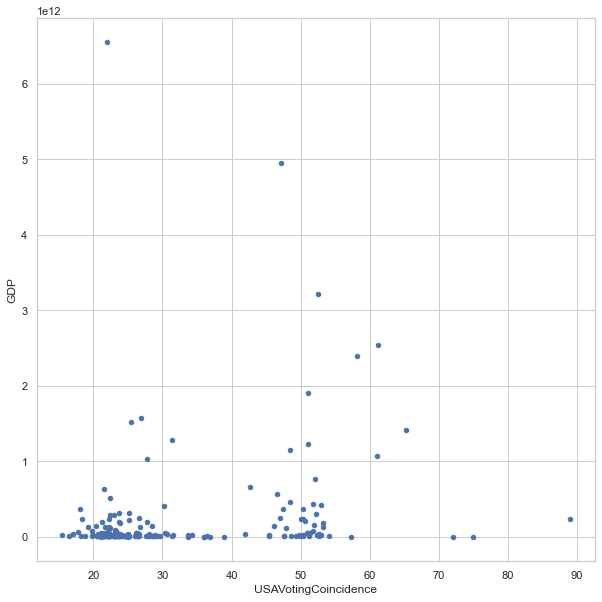

In [30]:
_ = cdf.plot(x='USAVotingCoincidence', y='GDP', kind='scatter', figsize=(10, 10))

In [31]:
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.cluster import KMeans

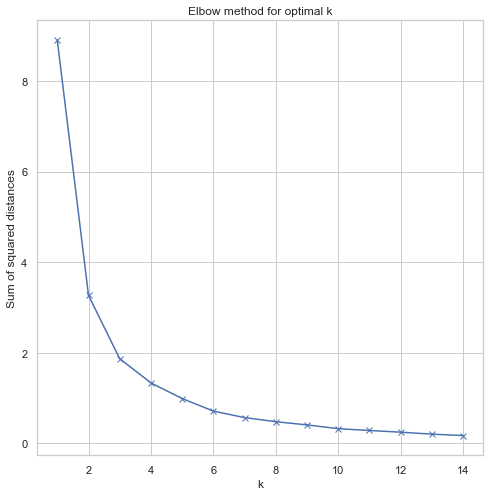

In [32]:
mms = MinMaxScaler()
mms.fit(cdf)
dat_trans = mms.transform(cdf)

ssd  = []
K = range(1,15)
for k in K:
    km = KMeans(n_clusters=k)
    km = km.fit(dat_trans)
    ssd.append(km.inertia_)

_ = pd.DataFrame(index=K, data=ssd).plot(figsize=(8, 8), marker='x', ylabel='Sum of squared distances', 
                                         xlabel='k', legend=False, title='Elbow method for optimal k')

In [33]:
sc = StandardScaler()
sc.fit(cdf)
X = sc.transform(cdf)

km = KMeans(init="random", n_clusters=4, n_init=10, max_iter=300, random_state=42)
km.fit(X)
labels = km.labels_
centroids = km.cluster_centers_

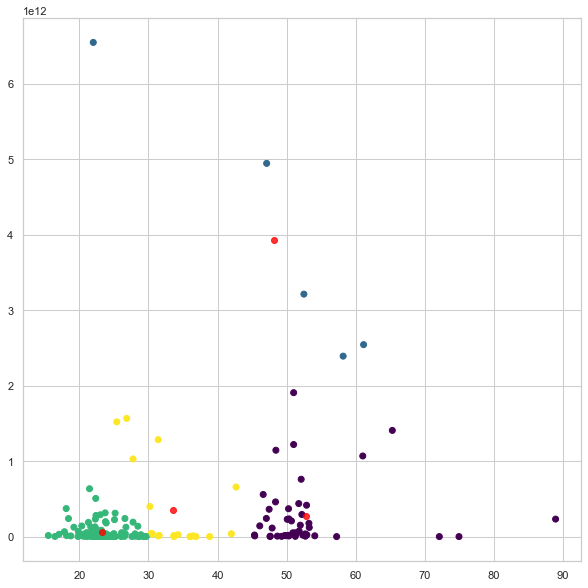

In [34]:
fig, ax = plt.subplots(figsize=(10, 10))
X = sc.inverse_transform(X)
centroids = sc.inverse_transform(km.cluster_centers_)
plt.scatter(X[:,0], X[:,1], c=labels, cmap='viridis')
plt.scatter(x=centroids[:,0], y=centroids[:,1], color='red', alpha=.8)

In [35]:
# Add the cluster labels to the original frame and save to csv format for geographical analysis in Tableau
cdf['Cluster'] = labels
cdf.reset_index().rename(columns={'index': 'CountryCode'}).to_csv('./CountryClusters.csv')